In [1]:
from __future__ import annotations

import os
import re
import shutil
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from config.config import RUN_DIR

In [52]:
def format_latex_label(text: str) -> str:
    # return text
    if not (text.startswith("$") and text.endswith("$")):
        text = f"${text}$"
    return text


def plot_detaild_analysis(
    metrics_df: pd.DataFrame,
    metric: str,
    run_col_name: str,
    experiment_col: str,
    left_col: str,
    right_col: str,
    left_col_name: str,
    right_col_name: str,
    run_separator: str = "__",
    precision: int = 2,
) -> None:
    metrics_df[run_col_name] = metrics_df[left_col].str.cat(metrics_df[right_col], sep=run_separator)

    metrics_df[left_col_name] = metrics_df[run_col_name].str.split(run_separator).str[0]
    metrics_df[right_col_name] = metrics_df[run_col_name].str.split(run_separator).str[1]

    fig, axes = plt.subplots(4, 2, figsize=(28, 34))
    fig.suptitle("Metric Analysis Across Models, Experiments, and Experiment Splits", fontsize=16)
    axes = axes.flatten()

    # 1. Box Plot + Points: {metric}s Per Model
    sns.boxplot(
        ax=axes[0],
        data=metrics_df,
        x=run_col_name,
        y=metric,
        palette="viridis",
        width=0.6,
        hue=run_col_name,
        legend=False,
    )
    sns.stripplot(ax=axes[0], data=metrics_df, x=run_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
    axes[0].set_title(f"{metric} Distribution Per {run_col_name}")
    axes[0].set_xticklabels([format_latex_label(t.get_text()) for t in axes[0].get_xticklabels()], rotation=34)

    # 2. Box Plot + Points: {metric}s Per Experiment Type
    sns.boxplot(
        ax=axes[1],
        data=metrics_df,
        x=experiment_col,
        y=metric,
        palette="coolwarm",
        width=0.6,
        hue=experiment_col,
        legend=False,
    )
    sns.stripplot(
        ax=axes[1], data=metrics_df, x=experiment_col, y=metric, color="black", alpha=0.5, jitter=True, size=4
    )
    axes[1].set_title(f"{metric} Distribution Per {experiment_col}")
    axes[1].set_xticklabels([format_latex_label(t.get_text()) for t in axes[1].get_xticklabels()], rotation=34)

    # 3. Heatmap: Metric Performance (Model vs. Experiment)
    pivot_table = metrics_df.pivot_table(index=run_col_name, columns=experiment_col, values=metric, sort=True)
    pivot_table = pivot_table.reindex(
        columns=metrics_df[experiment_col].unique(), index=metrics_df[run_col_name].unique()
    )

    sns.heatmap(ax=axes[2], data=pivot_table, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[2].set_title(f"{metric} Heatmap ({run_col_name} vs. {experiment_col})")
    axes[2].set_xlabel(format_latex_label(experiment_col))
    axes[2].set_ylabel(format_latex_label(run_col_name))
    axes[2].set_yticklabels([format_latex_label(t.get_text()) for t in axes[2].get_yticklabels()])
    axes[2].set_xticklabels([format_latex_label(t.get_text()) for t in axes[2].get_xticklabels()], rotation=34)

    # 4. Histogram: Overall Distribution of {metric}s
    sns.histplot(ax=axes[3], data=metrics_df[metric], bins=20, kde=True, color="purple")
    axes[3].set_title(f"Overall Distribution of {metric}s")
    axes[3].set_xlabel(format_latex_label(metric))
    axes[3].set_ylabel("Frequency")

    # 5. Heatmap: Metric Performance ({left_col} vs. {right_col})
    pivot_table_lr = metrics_df.pivot_table(index=left_col_name, columns=right_col_name, values=metric, sort=True)
    desired_order = metrics_df[left_col_name].unique()
    pivot_table_lr = pivot_table_lr.reindex(desired_order, axis=0)

    sns.heatmap(ax=axes[4], data=pivot_table_lr, cmap="Blues", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[4].set_title(f"Performance Heatmap ({left_col} vs. {right_col})")
    axes[4].set_xlabel(format_latex_label(right_col))
    axes[4].set_ylabel(format_latex_label(left_col))
    axes[4].set_yticklabels([format_latex_label(t.get_text()) for t in axes[4].get_yticklabels()])
    axes[4].set_xticklabels([format_latex_label(t.get_text()) for t in axes[4].get_xticklabels()], rotation=34)

    # 6. Heatmap: Model Performance by Left & {right_col}
    pivot_table_left = metrics_df.pivot_table(index=run_col_name, columns=left_col_name, values=metric)
    pivot_table_right = metrics_df.pivot_table(index=run_col_name, columns=right_col_name, values=metric)
    combined = pd.concat([pivot_table_left, pivot_table_right], axis=1)

    sns.heatmap(ax=axes[5], data=combined, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[5].set_title(f"Model Performance Heatmap (Grouped by {left_col})")
    axes[5].set_xlabel(format_latex_label(left_col))
    axes[5].set_ylabel(format_latex_label(run_col_name))
    axes[5].set_xticklabels([format_latex_label(t.get_text()) for t in axes[5].get_xticklabels()], rotation=34)
    axes[5].set_yticklabels([format_latex_label(t.get_text()) for t in axes[5].get_yticklabels()], rotation=0)

    # 7. Box Plot: {metric}s Grouped by {left_col}
    sns.boxplot(
        ax=axes[6],
        data=metrics_df,
        x=left_col_name,
        y=metric,
        palette="viridis",
        width=0.6,
        hue=left_col_name,
        legend=False,
    )
    sns.stripplot(ax=axes[6], data=metrics_df, x=left_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
    axes[6].set_title(f"{metric} Distribution (Grouped by {left_col})")
    axes[6].set_xlabel(format_latex_label(left_col))
    axes[6].set_xticklabels([format_latex_label(t.get_text()) for t in axes[6].get_xticklabels()], rotation=34)

    # 8. Box Plot: {metric}s Grouped by {right_col}
    sns.boxplot(
        ax=axes[7],
        data=metrics_df,
        x=right_col_name,
        y=metric,
        palette="coolwarm",
        width=0.6,
        hue=right_col_name,
        legend=False,
    )
    sns.stripplot(
        ax=axes[7], data=metrics_df, x=right_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4
    )
    axes[7].set_title(f"{metric} Distribution (Grouped by {right_col})")
    axes[7].set_xlabel(format_latex_label(right_col))
    axes[7].set_xticklabels([format_latex_label(t.get_text()) for t in axes[7].get_xticklabels()], rotation=34)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


In [56]:
prompts_map = {
    "direct_entity_ontological": "P",
    "sequential_hierarchy_ontological": "P_{EC}",
    "direct_entity": "P^{NLF}",
    "sequential_hierarchy": "P_{EC}^{NLF}",
    "direct_entity_with_synonyms": "P_{S}^{NLF}",
    "sequential_hierarchy_with_synonyms": "P_{EC+S}^{NLF}",
}

models_names_map = {
    "gemini-1.5-flash": "Flash.1.5",
    "gemini-2.0-flash": "Flash.2.0",
    "gemini-2.0-flash-lite": "Flash.2.0.lite",
    "gemini-2.5-flash-preview-04-17": "Flash.2.5",
    "gpt-4o-mini": "gpt.4o.mini",
}


def preprocess_metrics_df(metrics_df: pd.DataFrame) -> pd.DataFrame:
    metrics_df["Youden's index"] = metrics_df["Specificity"] + metrics_df["Sensitivity"] - 1
    metrics_df = metrics_df.rename(columns={"SubSet": "Matching Task"})

    if "Prompt" not in metrics_df.columns:
        metrics_df["Prompt"] = None

    if "Experiment" in metrics_df.columns:
        metrics_df.loc[metrics_df["Prompt"].isna(), "Prompt"] = metrics_df.loc[
            metrics_df["Prompt"].isna(), "Experiment"
        ]

    metrics_df["Model"] = metrics_df["Model"].map(models_names_map)
    metrics_df["Prompt"] = metrics_df["Prompt"].map(prompts_map)

    metrics_df["Matching Task"] = pd.Categorical(
        metrics_df["Matching Task"], categories=metrics_df["Matching Task"].unique(), ordered=True
    )
    metrics_df["Prompt"] = pd.Categorical(metrics_df["Prompt"], categories=list(prompts_map.values()), ordered=True)
    return metrics_df.sort_values(["Model", "Matching Task", "Prompt"])

In [57]:
metrics_df = preprocess_metrics_df(pd.read_csv(RUN_DIR / "all_runs_metrics_new.csv"))

metrics_df.head(40)

,Prompt,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Youden's index,Dataset,Matching Task,Model,Run
1,P,0.8116,0.7989,0.9932,0.8855,0.3113,0.9932,0.3045,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
3,P_{EC},0.7789,0.7727,0.9897,0.8679,0.1981,0.9897,0.1878,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
0,P^{NLF},0.8116,0.7989,0.9932,0.8855,0.3113,0.9932,0.3045,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
2,P_{EC}^{NLF},0.7965,0.7890,0.9863,0.8767,0.2736,0.9863,0.2599,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
4,P_{S}^{NLF},0.8116,0.7989,0.9932,0.8855,0.3113,0.9932,0.3045,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
5,P_{EC+S}^{NLF},0.8090,0.7983,0.9897,0.8838,0.3113,0.9897,0.3010,anatomy,human-mouse,Flash.1.5,2025-05-10_23-56-32
31,P,0.6410,0.6157,0.9845,0.7576,0.1862,0.9845,0.1707,bioml-2024,ncit-doid,Flash.1.5,2025-05-11_00-12-18
33,P_{EC},0.6178,0.6007,0.9817,0.7453,0.1359,0.9817,0.1176,bioml-2024,ncit-doid,Flash.1.5,2025-05-11_00-12-18
30,P^{NLF},0.6522,0.6242,0.9789,0.7623,0.2197,0.9789,0.1986,bioml-2024,ncit-doid,Flash.1.5,2025-05-11_00-12-18
32,P_{EC}^{NLF},0.6514,0.6221,0.9887,0.7637,0.2048,0.9887,0.1935,bioml-2024,ncit-doid,Flash.1.5,2025-05-11_00-12-18


/tmp/ipykernel_37085/945152910.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([format_latex_label(t.get_text()) for t in axes[0].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/945152910.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([format_latex_label(t.get_text()) for t in axes[1].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/945152910.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[6].set_xticklabels([format_latex_label(t.get_text()) for t in axes[6].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/945152910.py:136: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax

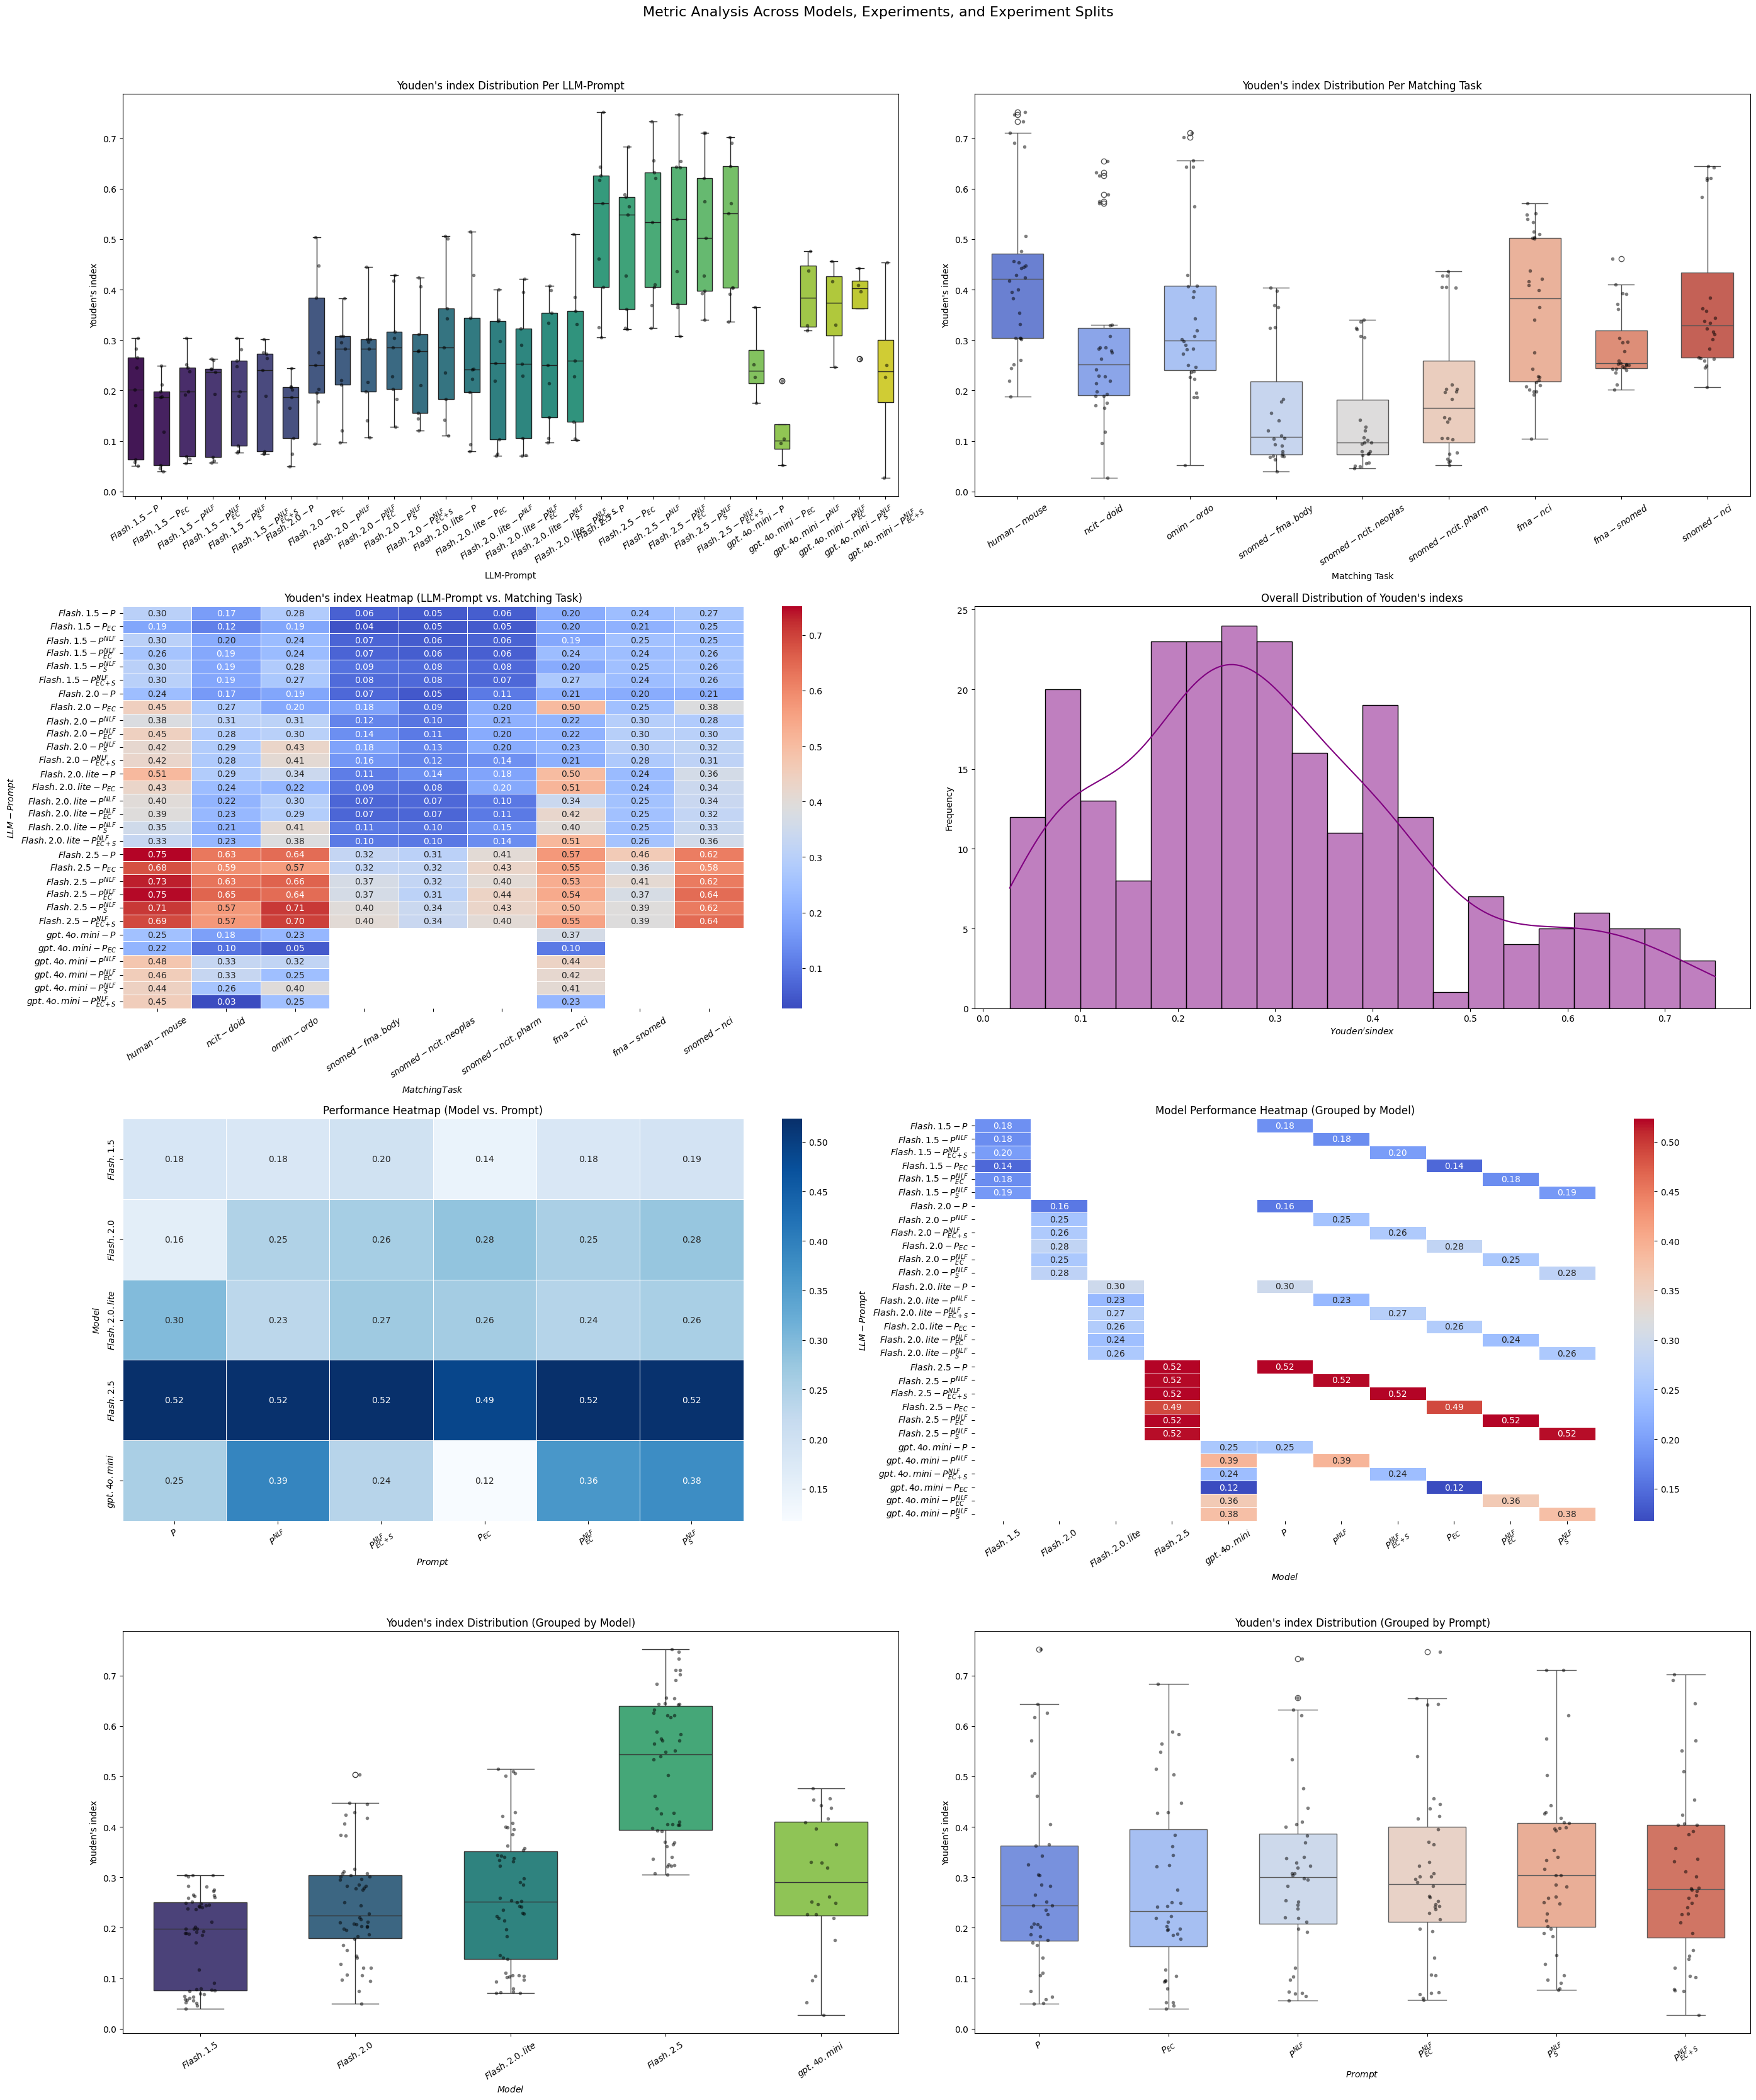

In [58]:
metric = "Youden's index"
# metric = "F1 Score"
experiment_col, left_col, right_col = "Matching Task", "Model", "Prompt"

plot_detaild_analysis(
    metrics_df=metrics_df,
    metric=metric,
    run_col_name="LLM-Prompt",
    experiment_col=experiment_col,
    left_col=left_col,
    right_col=right_col,
    left_col_name="leftPart",
    right_col_name="rightPart",
    run_separator="-",
)

### Copy best results

In [ ]:
prompt_type = "direct_entity_with_synonyms"
model = "gemini-2.0-flash_"

RUNS_METADATA = [
    ("2025-05-01_11-47-16", "gemini-2.0-flash", "snomed-nci", "largebio"),
    ("2025-05-01_11-37-30", "gemini-2.0-flash-lite", "snomed-nci", "largebio"),
    ("2025-05-01_11-24-31", "gemini-2.0-flash", "fma-snomed", "largebio"),
    ("2025-05-01_11-19-48", "gemini-2.0-flash-lite", "fma-snomed", "largebio"),
    ("2025-05-01_11-15-05", "gemini-2.0-flash", "snomed-ncit.pharm", "bioml-2024"),
    ("2025-05-01_11-12-35", "gemini-2.0-flash-lite", "snomed-ncit.pharm", "bioml-2024"),
    ("2025-05-01_11-07-00", "gemini-2.0-flash", "snomed-ncit.neoplas", "bioml-2024"),
    ("2025-05-01_11-06-39", "gemini-2.0-flash-lite", "snomed-ncit.neoplas", "bioml-2024"),
    ("2025-05-01_10-56-46", "gemini-2.0-flash", "snomed-fma.body", "bioml-2024"),
    ("2025-05-01_10-50-33", "gemini-2.0-flash-lite", "snomed-fma.body", "bioml-2024"),
    ("2025-05-01_10-13-02", "gemini-2.0-flash-lite", "fma-snomed", "largebio"),
    ("2025-04-10_22-11-36", "gemini-2.0-flash", "ncit-doid", "bioml-2024"),
    ("2025-04-10_00-33-19", "gemini-2.0-flash-lite", "ncit-doid", "bioml-2024"),
    ("2025-04-06_22-05-02", "gemini-2.0-flash-lite", "omim-ordo", "bioml-2024"),
    ("2025-04-06_19-27-41", "gemini-2.0-flash", "omim-ordo", "bioml-2024"),
    ("2025-04-06_14-51-00", "gemini-2.0-flash-lite", "fma-nci", "largebio"),
    ("2025-04-06_14-18-46", "gemini-2.0-flash", "fma-nci", "largebio"),
    ("2025-04-04_19-41-28", "gemini-2.0-flash", "human-mouse", "anatomy"),
    ("2025-04-04_19-23-47", "gemini-2.0-flash-lite", "human-mouse", "anatomy"),
    ("2025-04-04_00-43-16", "gemini-2.0-flash", "fma-snomed", "largebio"),
    ("2025-03-28_10-15-04", "gpt-4o-mini", "fma-nci", "largebio"),
    ("2025-03-19_23-32-20", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
    ("2025-03-19_22-17-52", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-19_19-48-41", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-14_00-40-55", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-12_17-21-53", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-12_14-43-32", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
]


In [29]:
for run_metadata in RUNS_METADATA:
    run_name, model_name, subset_name, experiment_name = run_metadata
    run_dir = Path("../runs") / run_name
    for file in run_dir.iterdir():
        if prompt_type in file and model in file and file.endswith(".csv"):
            print(f"Processing {file} in {file}")
            new_file_path = Path("best_results") / file
            new_file_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(run_dir / file, new_file_path)

Processing snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-ncit.n

## Gather outputs results

In [22]:
outputs_dir = Path("./outputs")
datasets_map = {"anatomy": ["human-mouse"], "largebio": ["fma-nci"], "bioml-2024": ["omim-ordo"]}
models = ["gemini-2.0-flash-lite", "gemini-2.0-flash"]
experiments_subtypes = {"syspromts" : ["base", "natural_language", "ontology_aware", "synonym_aware", "none"]}
# experiments_subtypes = {"determinism" : ["0", "1", "2", "3"]}

dfs = []

for dataset, subsets_map in datasets_map.items():
    for set_name in subsets_map:
        for model in models:
            for experiment_type in experiments_subtypes:
                for experiment in experiments_subtypes[experiment_type]:
                    run_subdir = f"{dataset}/{set_name}/{model}/{experiment_type}/{experiment}"
                    metrics_df = pd.read_csv(outputs_dir / run_subdir / "results.csv")

                    for col, value in zip(["Dataset", "SubSet", "Model", "ExperimentType", "ExpName"
                                           ], [dataset, set_name, model, experiment_type, experiment]):
                        if col not in metrics_df.columns:
                            metrics_df[col] = value

                    metrics_df["Run"] = run_subdir
                    dfs.append(metrics_df)

results_df = pd.concat(dfs, ignore_index=True)
results_df = results_df.sort_values(by=["Dataset", "SubSet", "Model"])

In [23]:
results_df

,Prompt,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,SubSet,Model,ExperimentType,ExpName,Run
30,direct_entity,0.8819,0.8769,0.9760,0.9238,0.6226,0.9760,anatomy,human-mouse,gemini-2.0-flash,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...
31,direct_entity_ontological,0.7714,0.8792,0.7979,0.8366,0.6981,0.7979,anatomy,human-mouse,gemini-2.0-flash,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...
32,sequential_hierarchy,0.8367,0.8348,0.9692,0.8970,0.4717,0.9692,anatomy,human-mouse,gemini-2.0-flash,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...
33,sequential_hierarchy_ontological,0.8116,0.8444,0.9110,0.8764,0.5377,0.9110,anatomy,human-mouse,gemini-2.0-flash,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...
34,direct_entity_with_synonyms,0.8492,0.8372,0.9863,0.9057,0.4717,0.9863,anatomy,human-mouse,gemini-2.0-flash,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,direct_entity_ontological,0.7222,0.9063,0.7474,0.8192,0.5873,0.7474,largebio,fma-nci,gemini-2.0-flash-lite,syspromts,none,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...
86,sequential_hierarchy,0.7760,0.9244,0.7994,0.8574,0.6508,0.7994,largebio,fma-nci,gemini-2.0-flash-lite,syspromts,none,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...
87,sequential_hierarchy_ontological,0.5006,0.9202,0.4458,0.6006,0.7937,0.4458,largebio,fma-nci,gemini-2.0-flash-lite,syspromts,none,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...
88,direct_entity_with_synonyms,0.6959,0.9283,0.6924,0.7932,0.7143,0.6924,largebio,fma-nci,gemini-2.0-flash-lite,syspromts,none,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...


In [24]:
preprocess_metrics_df(results_df)

,Prompt,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,Matching Task,Model,ExperimentType,ExpName,Run,Youden's index
31,P,0.7714,0.8792,0.7979,0.8366,0.6981,0.7979,anatomy,human-mouse,Flash.2.0,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4960
37,P,0.7940,0.7853,0.9897,0.8758,0.2547,0.9897,anatomy,human-mouse,Flash.2.0,syspromts,natural_language,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.2444
43,P,0.8492,0.8718,0.9315,0.9007,0.6226,0.9315,anatomy,human-mouse,Flash.2.0,syspromts,ontology_aware,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.5541
49,P,0.8191,0.8526,0.9110,0.8808,0.5660,0.9110,anatomy,human-mouse,Flash.2.0,syspromts,synonym_aware,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4770
55,P,0.8040,0.8664,0.8664,0.8664,0.6321,0.8664,anatomy,human-mouse,Flash.2.0,syspromts,none,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,P_{EC+S}^{NLF},0.8486,0.9083,0.9123,0.9103,0.5079,0.9123,largebio,fma-nci,Flash.2.0.lite,syspromts,base,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...,0.4202
71,P_{EC+S}^{NLF},0.8636,0.8842,0.9643,0.9225,0.3254,0.9643,largebio,fma-nci,Flash.2.0.lite,syspromts,natural_language,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...,0.2897
77,P_{EC+S}^{NLF},0.8673,0.8921,0.9584,0.9241,0.3810,0.9584,largebio,fma-nci,Flash.2.0.lite,syspromts,ontology_aware,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...,0.3394
83,P_{EC+S}^{NLF},0.8586,0.8867,0.9539,0.9191,0.3492,0.9539,largebio,fma-nci,Flash.2.0.lite,syspromts,synonym_aware,largebio/fma-nci/gemini-2.0-flash-lite/sysprom...,0.3031


/tmp/ipykernel_37085/438474466.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([format_latex_label(t.get_text()) for t in axes[0].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/438474466.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([format_latex_label(t.get_text()) for t in axes[1].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/438474466.py:117: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[6].set_xticklabels([format_latex_label(t.get_text()) for t in axes[6].get_xticklabels()], rotation=34)
/tmp/ipykernel_37085/438474466.py:135: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax

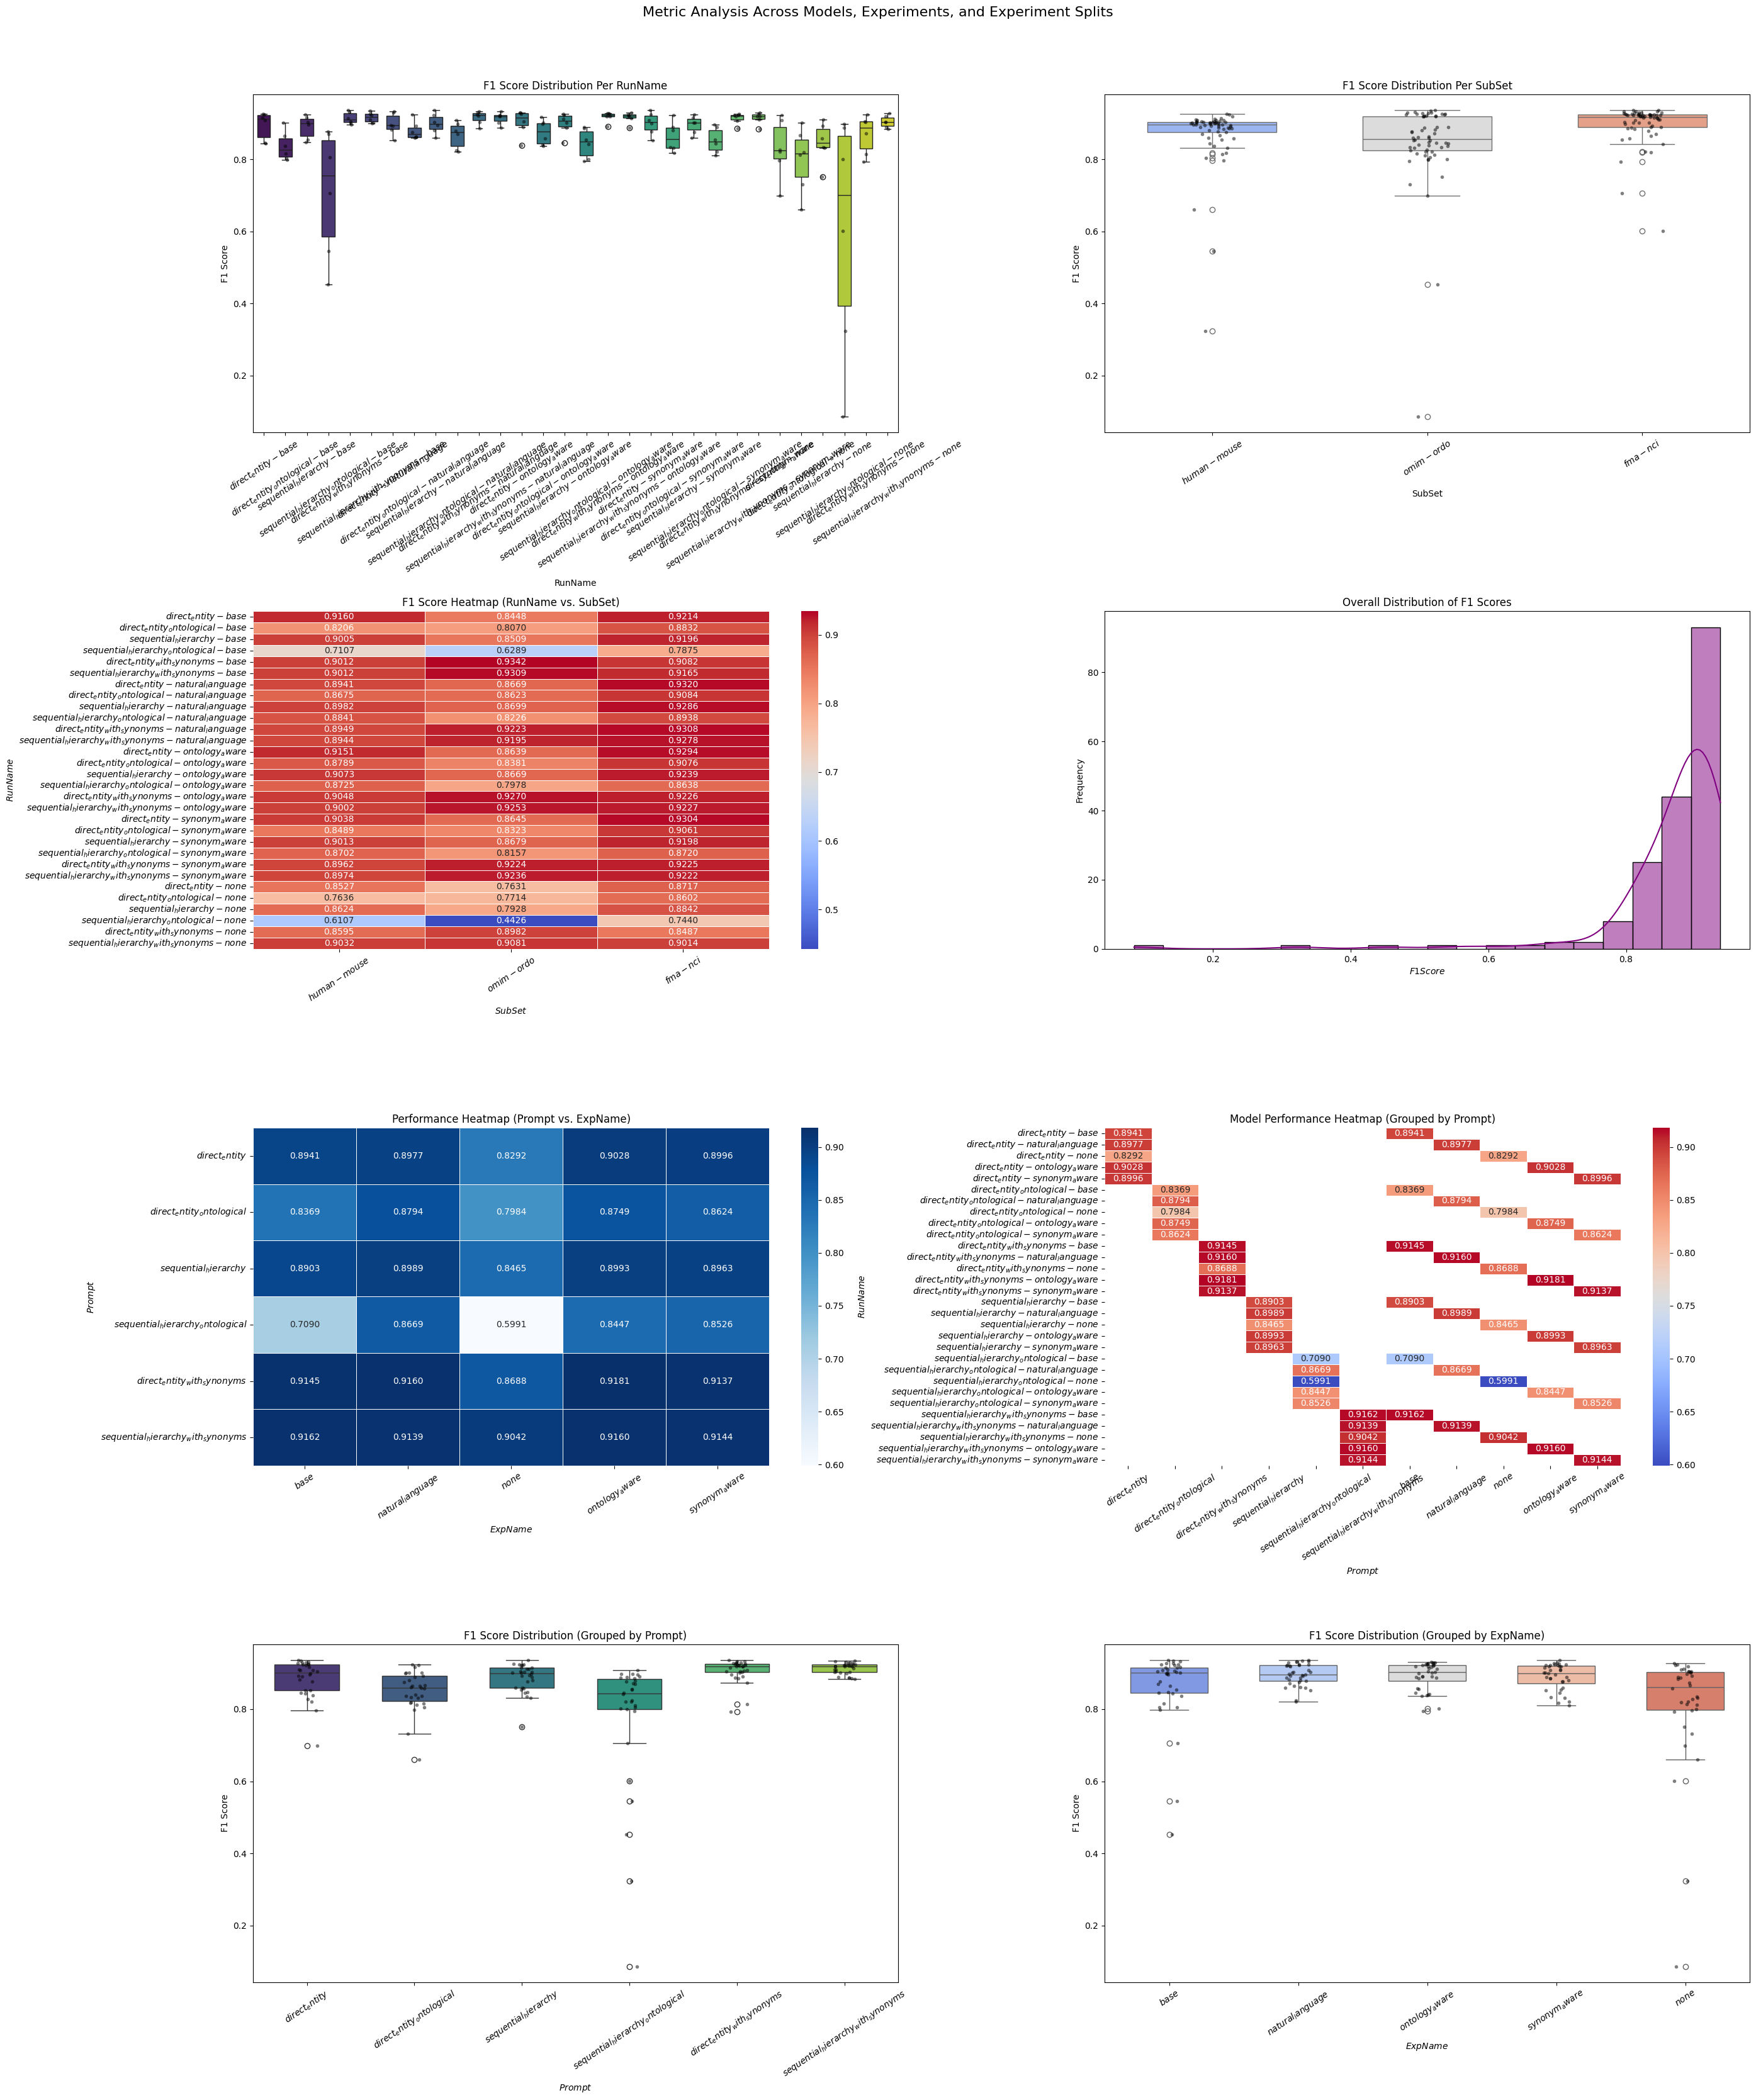

In [28]:
metrics_df = results_df.copy()
metric = "F1 Score"

experiment_col, left_col, right_col = "SubSet", "Prompt", "ExpName"

plot_detaild_analysis(
    metrics_df=metrics_df,
    metric=metric,
    run_col_name="RunName",
    experiment_col=experiment_col,
    left_col=left_col,
    right_col=right_col,
    left_col_name="leftPart",
    right_col_name="rightPart",
    run_separator="-",
    precision=4,
)